In [1]:
import sys
sys.path.append('/home/pavel/pyadi-iio/')
sys.path.append('/home/pavel/libiio')
import adi
import matplotlib.pyplot as plt
import numpy as np

In [6]:
# Create radio
sdr = adi.ad9363("ip:192.168.2.2")
samp_rate = 30.72e6

'''Configure Rx properties'''
sdr.rx_enabled_channels = [0, 1]
sdr.sample_rate = int(samp_rate)
sdr.rx_rf_bandwidth = int(30.72e6)
sdr.rx_lo = int(3.19e9)
sdr.rx_buffer_size = 35000
sdr.gain_control_mode_chan0 = "manual"
sdr.gain_control_mode_chan1 = "manual"
sdr.rx_hardwaregain_chan0 = int(40)
sdr.rx_hardwaregain_chan1 = int(40)

In [7]:
sig = sdr.rx()

In [8]:
sig = np.asarray(sig)

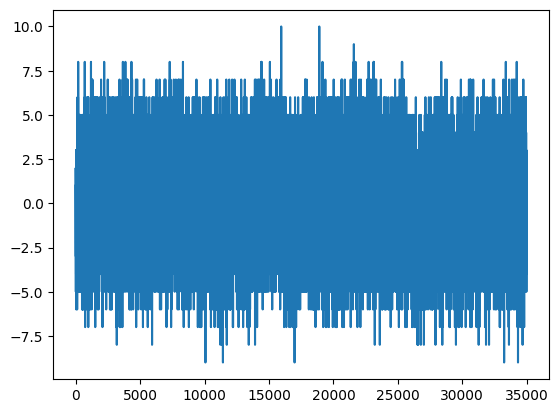

In [9]:
plt.plot(sig[0])
plt.show()

In [10]:
spec = np.fft.fft(sig[0])

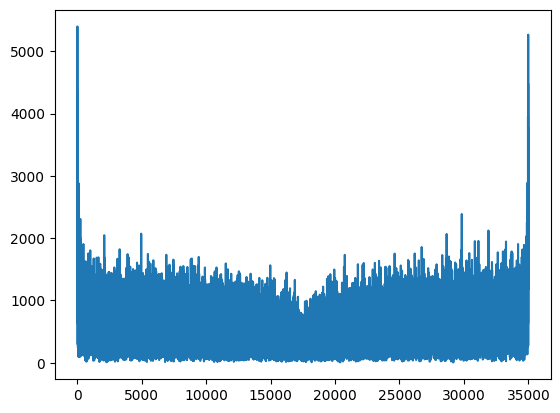

In [11]:
plt.plot(np.abs(spec))
plt.show()

In [12]:
spec[2000:6000] = 0

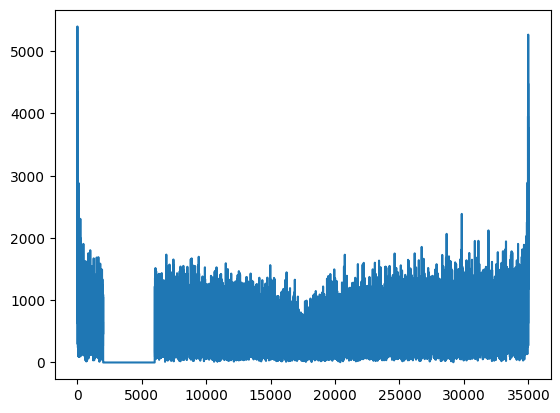

In [13]:
plt.plot(np.abs(spec))
plt.show()

In [14]:
sig_back = np.fft.ifft(spec)

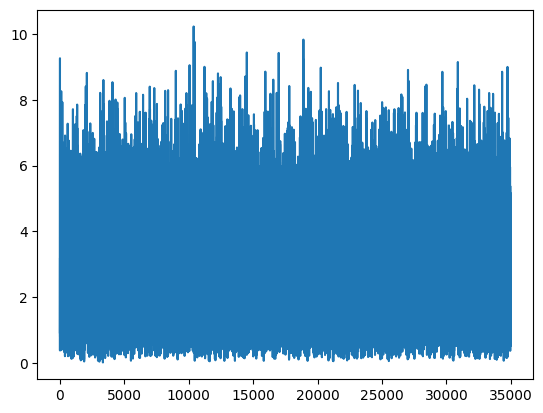

In [15]:
plt.plot(np.abs(sig_back))
plt.show()